# 03d - Graphs and Final Evaluation
Rebuilds results from saved logs and checkpoints on Drive. Requires Step A, Step B, and Step C to have finished.

**Cell 1:** Install libraries, mount Drive, restore patches from the zip backup.

In [1]:
!pip install -q segmentation-models-pytorch torchgeo rasterio

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
import zipfile
import time

DRIVE_FOLDER = '/content/drive/MyDrive/lulc_dataset'
PATCH_FOLDER = '/content/local_patches'
CKPT_DIR = f'{DRIVE_FOLDER}/All Model Weights'
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(PATCH_FOLDER, exist_ok=True)

t0 = time.time()
shutil.copy(f'{DRIVE_FOLDER}/patches_backup.zip', '/content/patches_backup.zip')
print(f'Downloaded zip from Drive in {time.time()-t0:.0f}s')

t0 = time.time()
with zipfile.ZipFile('/content/patches_backup.zip') as z:
    z.extractall(PATCH_FOLDER)
print(f'Extracted locally in {time.time()-t0:.0f}s')

print('Local patch folder (used for training):', PATCH_FOLDER)
print('Checkpoint folder:', CKPT_DIR)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
Downloaded zip from Drive in 174s
Extracted locally in 162s
Local patch folder (used for training): /content/local_patches
Checkpoint folder: /content/drive/MyDrive/lulc_dataset/All Model Weights


**Cell 2:** Load patch metadata, split into train/val/3 test sets.

In [2]:
import pandas as pd

patch_df = pd.read_csv(f'{DRIVE_FOLDER}/patch_metadata.csv')
print(f'Loaded {len(patch_df)} total patch records')
print(patch_df['split'].value_counts())

train_df = patch_df[patch_df['split'] == 'train'].reset_index(drop=True)
val_df = patch_df[patch_df['split'] == 'val'].reset_index(drop=True)
test_same_region_df = patch_df[patch_df['split'] == 'test_same_region'].reset_index(drop=True)
test_similar_unseen_df = patch_df[patch_df['split'] == 'test_similar_unseen'].reset_index(drop=True)
test_dissimilar_df = patch_df[patch_df['split'] == 'test_dissimilar'].reset_index(drop=True)

print(f'\ntrain={len(train_df)} val={len(val_df)} test_same_region={len(test_same_region_df)} '
      f'test_similar_unseen={len(test_similar_unseen_df)} test_dissimilar={len(test_dissimilar_df)}')


Loaded 12288 total patch records
split
train                  7680
test_dissimilar        1536
test_similar_unseen    1152
unassigned              768
test_same_region        768
val                     384
Name: count, dtype: int64

train=7680 val=384 test_same_region=768 test_similar_unseen=1152 test_dissimilar=1536


**Cell 3:** Define the 9 classes, remap raw pixel codes.

In [3]:
import numpy as np

RAW_CODES = [10, 20, 30, 40, 50, 60, 80, 90, 95]
CLASS_NAMES = [
    "Tree cover", "Shrubland", "Grassland", "Cropland", "Built-up",
    "Bare/sparse vegetation", "Permanent water", "Herbaceous wetland", "Mangroves",
]
NUM_CLASSES = len(RAW_CODES)
IGNORE_INDEX = 255
RARE_CLASSES = ["Shrubland", "Bare/sparse vegetation", "Herbaceous wetland", "Mangroves"]

_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for i, code_val in enumerate(RAW_CODES):
    _LUT[code_val] = i

def remap_label(label_array):
    label_array = np.clip(label_array.astype(np.int64), 0, 255)
    return _LUT[label_array]

print('Classes used for training:', CLASS_NAMES)


Classes used for training: ['Tree cover', 'Shrubland', 'Grassland', 'Cropland', 'Built-up', 'Bare/sparse vegetation', 'Permanent water', 'Herbaceous wetland', 'Mangroves']


**Cell 4:** Dataset class.

In [4]:
import time
import torch
from torch.utils.data import Dataset


class PatchDataset(Dataset):
    """add_vv_vh_diff=True appends a 3rd channel (VV-VH) for SegNet/FCDenseNet,
    which expect 3-channel ImageNet-style input. The 6 ResNet-50 models stay
    2-channel to match their pretrained first convolution."""

    def __init__(self, df, patch_folder, augment=False, oversample_rare=False,
                 image_col='image_patch', label_col='label_patch', add_vv_vh_diff=False):
        self.patch_folder = patch_folder
        self.augment = augment
        self.image_col = image_col
        self.label_col = label_col
        self.add_vv_vh_diff = add_vv_vh_diff

        if oversample_rare:
            if 'is_rare' not in df.columns:
                raise ValueError("oversample_rare=True needs tag_rare_patches() run on this df first.")
            rare_rows = df[df['is_rare']]
            if len(rare_rows) > 0:
                df = pd.concat([df, rare_rows, rare_rows], ignore_index=True)
        self.rows = df.reset_index(drop=True)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows.iloc[idx]
        img = np.load(f'{self.patch_folder}/{row[self.image_col]}').astype(np.float32)
        lbl_raw = np.load(f'{self.patch_folder}/{row[self.label_col]}')
        lbl = remap_label(lbl_raw)

        if self.add_vv_vh_diff:
            if img.shape[0] != 2:
                raise ValueError(f'add_vv_vh_diff expects a 2-channel patch, got shape {img.shape}')
            vv_vh_diff = (img[0] - img[1])[np.newaxis, :, :]
            img = np.concatenate([img, vv_vh_diff], axis=0)

        if self.augment:
            if np.random.rand() > 0.5:
                img = np.flip(img, axis=2).copy()
                lbl = np.flip(lbl, axis=1).copy()
            if np.random.rand() > 0.5:
                img = np.flip(img, axis=1).copy()
                lbl = np.flip(lbl, axis=0).copy()
            k = np.random.choice([0, 1, 2, 3])
            img = np.rot90(img, k, axes=(1, 2)).copy()
            lbl = np.rot90(lbl, k, axes=(0, 1)).copy()

        return torch.from_numpy(img).float(), torch.from_numpy(lbl).long()


print('PatchDataset ready.')


PatchDataset ready.


**Cell 5:** Metrics: mIoU, per-class IoU/F1, macro-F1, kappa.

In [5]:
def compute_confusion_matrix(preds, targets, num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX):
    if torch.is_tensor(preds):
        preds = preds.cpu().numpy()
    if torch.is_tensor(targets):
        targets = targets.cpu().numpy()
    valid = targets != ignore_index
    preds = preds[valid]
    targets = targets[valid]
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    idx = targets * num_classes + preds
    binc = np.bincount(idx, minlength=num_classes * num_classes)
    cm += binc[: num_classes * num_classes].reshape(num_classes, num_classes)
    return cm


def metrics_from_confusion_matrix(cm):
    tp = np.diag(cm).astype(np.float64)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    total = cm.sum()

    oa = tp.sum() / total if total > 0 else 0.0

    union = tp + fp + fn
    iou = np.divide(tp, union, out=np.zeros_like(tp), where=union > 0)
    present = union > 0
    miou = iou[present].mean() if present.any() else 0.0

    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                    out=np.zeros_like(tp), where=(precision + recall) > 0)
    macro_f1 = f1[present].mean() if present.any() else 0.0

    row_sum = cm.sum(axis=1)
    col_sum = cm.sum(axis=0)
    expected = (row_sum * col_sum).sum() / total if total > 0 else 0.0
    kappa = (tp.sum() - expected) / (total - expected) if (total - expected) != 0 else 0.0

    return {
        'OA': float(oa), 'mIoU': float(miou), 'macro_F1': float(macro_f1), 'kappa': float(kappa),
        'per_class_IoU': iou.tolist(), 'per_class_F1': f1.tolist(),
    }

print('Metrics functions ready.')


Metrics functions ready.


**Cell 6:** SegNet architecture.

In [6]:
import torchvision

class SegNet(torch.nn.Module):
    def __init__(self, in_channels=3, num_classes=9, pretrained=True):
        super().__init__()
        weights = torchvision.models.VGG16_BN_Weights.IMAGENET1K_V1 if pretrained else None
        vgg16 = torchvision.models.vgg16_bn(weights=weights)
        features = list(vgg16.features.children())

        if in_channels != 3:
            old_conv = features[0]
            new_conv = torch.nn.Conv2d(
                in_channels, old_conv.out_channels,
                kernel_size=old_conv.kernel_size, stride=old_conv.stride, padding=old_conv.padding,
            )
            if pretrained:
                with torch.no_grad():
                    if in_channels <= 3:
                        new_conv.weight[:] = old_conv.weight[:, :in_channels, :, :].clone()
                    else:
                        reps = (in_channels + 2) // 3
                        tiled = old_conv.weight.repeat(1, reps, 1, 1)[:, :in_channels, :, :]
                        new_conv.weight[:] = tiled.clone()
            features[0] = new_conv

        self.encoder_stages = torch.nn.ModuleList()
        stage_layers = []
        for layer in features:
            if isinstance(layer, torch.nn.MaxPool2d):
                self.encoder_stages.append(torch.nn.Sequential(*stage_layers))
                stage_layers = []
            else:
                stage_layers.append(layer)
        assert len(self.encoder_stages) == 5
        self.pool = torch.nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True)

        decoder_configs = [(512, 512, 3), (512, 256, 3), (256, 128, 3), (128, 64, 2), (64, 64, 2)]
        self.decoder_stages = torch.nn.ModuleList()
        for in_c, out_c, n_convs in decoder_configs:
            layers = []
            ch = in_c
            for i in range(n_convs):
                out = out_c if i == n_convs - 1 else ch
                layers += [torch.nn.Conv2d(ch, out, 3, padding=1), torch.nn.BatchNorm2d(out), torch.nn.ReLU(inplace=True)]
                ch = out
            self.decoder_stages.append(torch.nn.Sequential(*layers))

        self.final_conv = torch.nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        pool_indices = []
        pre_pool_sizes = []
        for stage in self.encoder_stages:
            x = stage(x)
            pre_pool_sizes.append(x.size())
            x, idx = self.pool(x)
            pool_indices.append(idx)

        for i, stage in enumerate(self.decoder_stages):
            idx = pool_indices[-(i + 1)]
            size = pre_pool_sizes[-(i + 1)]
            x = torch.nn.functional.max_unpool2d(x, idx, kernel_size=2, stride=2, output_size=size)
            x = stage(x)

        return self.final_conv(x)

print('SegNet class ready.')


SegNet class ready.


**Cell 7:** FC-DenseNet architecture.

In [7]:
class DenseLayer(torch.nn.Module):
    def __init__(self, in_channels, growth_rate, dropout=0.2):
        super().__init__()
        self.bn = torch.nn.BatchNorm2d(in_channels)
        self.relu = torch.nn.ReLU(inplace=True)
        self.conv = torch.nn.Conv2d(in_channels, growth_rate, kernel_size=3, padding=1, bias=False)
        self.drop = torch.nn.Dropout2d(dropout)

    def forward(self, x):
        return self.drop(self.conv(self.relu(self.bn(x))))


class DenseBlock(torch.nn.Module):
    def __init__(self, in_channels, growth_rate, n_layers, dropout=0.2):
        super().__init__()
        self.layers = torch.nn.ModuleList([
            DenseLayer(in_channels + i * growth_rate, growth_rate, dropout)
            for i in range(n_layers)
        ])

    def forward(self, x):
        new_features = []
        for layer in self.layers:
            out = layer(x)
            new_features.append(out)
            x = torch.cat([x, out], dim=1)
        new_only = torch.cat(new_features, dim=1)
        return x, new_only


class TransitionDown(torch.nn.Module):
    def __init__(self, channels, dropout=0.2):
        super().__init__()
        self.bn = torch.nn.BatchNorm2d(channels)
        self.relu = torch.nn.ReLU(inplace=True)
        self.conv = torch.nn.Conv2d(channels, channels, kernel_size=1, bias=False)
        self.drop = torch.nn.Dropout2d(dropout)
        self.pool = torch.nn.MaxPool2d(2)

    def forward(self, x):
        x = self.drop(self.conv(self.relu(self.bn(x))))
        return self.pool(x)


class TransitionUp(torch.nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.convT = torch.nn.ConvTranspose2d(channels, channels, kernel_size=3, stride=2, padding=1, output_padding=1)

    def forward(self, x, target_size):
        x = self.convT(x)
        if x.shape[-2:] != target_size:
            x = torch.nn.functional.interpolate(x, size=target_size, mode='nearest')
        return x


class FCDenseNet56(torch.nn.Module):
    def __init__(self, in_channels=3, num_classes=9, growth_rate=12, n_layers_per_block=4,
                 n_blocks=5, n_init_features=48, dropout=0.2):
        super().__init__()
        self.init_conv = torch.nn.Conv2d(in_channels, n_init_features, kernel_size=3, padding=1, bias=False)

        cur_channels = n_init_features
        self.down_blocks = torch.nn.ModuleList()
        self.trans_down = torch.nn.ModuleList()
        skip_channels = []
        for _ in range(n_blocks):
            self.down_blocks.append(DenseBlock(cur_channels, growth_rate, n_layers_per_block, dropout))
            cur_channels = cur_channels + n_layers_per_block * growth_rate
            skip_channels.append(n_layers_per_block * growth_rate)
            self.trans_down.append(TransitionDown(cur_channels, dropout))

        self.bottleneck = DenseBlock(cur_channels, growth_rate, n_layers_per_block, dropout)
        up_channels = n_layers_per_block * growth_rate

        self.trans_up = torch.nn.ModuleList()
        self.up_blocks = torch.nn.ModuleList()
        for i in reversed(range(n_blocks)):
            self.trans_up.append(TransitionUp(up_channels))
            concat_channels = up_channels + skip_channels[i]
            self.up_blocks.append(DenseBlock(concat_channels, growth_rate, n_layers_per_block, dropout))
            up_channels = n_layers_per_block * growth_rate

        self.final_conv = torch.nn.Conv2d(up_channels, num_classes, kernel_size=1)

    def forward(self, x):
        x = self.init_conv(x)

        skips = []
        skip_sizes = []
        for down_block, td in zip(self.down_blocks, self.trans_down):
            x, new_only = down_block(x)
            skips.append(new_only)
            skip_sizes.append(new_only.shape[-2:])
            x = td(x)

        _, x = self.bottleneck(x)

        for i, (tu, up_block) in enumerate(zip(self.trans_up, self.up_blocks)):
            skip = skips[-(i + 1)]
            size = skip_sizes[-(i + 1)]
            x = tu(x, size)
            x = torch.cat([x, skip], dim=1)
            _, x = up_block(x)

        return self.final_conv(x)

print('FCDenseNet56 class ready.')


FCDenseNet56 class ready.


**Cell 8:** `build_model()`: rebuilds any of the 8 architectures for evaluation.

In [8]:
import segmentation_models_pytorch as smp
import torchgeo.models as tgm

SMP_BUILDERS = {
    'Unet': smp.Unet, 'UnetPlusPlus': smp.UnetPlusPlus, 'MAnet': smp.MAnet,
    'DeepLabV3Plus': smp.DeepLabV3Plus, 'FPN': smp.FPN, 'PSPNet': smp.PSPNet,
}

TORCHGEO_SAR_WEIGHTS = {
    'ssl4eo_moco': 'SENTINEL1_ALL_MOCO',
    'softcon': 'SENTINEL1_GRD_SOFTCON',
}


def _load_resnet50_sar_encoder(smp_model, weights_name, freeze=False):
    """strict=True: nn.Module.load_state_dict always raises a RuntimeError on
    any real key mismatch, regardless of smp's own encoder override discarding
    the return value, so a genuine incompatibility still fails loudly."""
    weights_enum = getattr(tgm.ResNet50_Weights, weights_name)
    state_dict = weights_enum.get_state_dict(progress=True)
    smp_model.encoder.load_state_dict(state_dict, strict=True)
    if freeze:
        for p in smp_model.encoder.parameters():
            p.requires_grad = False
    return smp_model


def build_model(architecture, encoder_source, num_classes=NUM_CLASSES, in_channels=2, freeze_encoder=False):
    if architecture == 'SegNet':
        pretrained = encoder_source != 'random'
        return SegNet(in_channels=3, num_classes=num_classes, pretrained=pretrained)

    if architecture == 'FCDenseNet':
        return FCDenseNet56(in_channels=3, num_classes=num_classes)

    if architecture not in SMP_BUILDERS:
        raise ValueError(f'Unknown architecture: {architecture}')

    builder = SMP_BUILDERS[architecture]

    if encoder_source == 'imagenet':
        model = builder(encoder_name='resnet50', encoder_weights='imagenet',
                         in_channels=in_channels, classes=num_classes)
        if freeze_encoder:
            for p in model.encoder.parameters():
                p.requires_grad = False
        return model

    if encoder_source == 'random':
        return builder(encoder_name='resnet50', encoder_weights=None,
                        in_channels=in_channels, classes=num_classes)

    if encoder_source in TORCHGEO_SAR_WEIGHTS:
        model = builder(encoder_name='resnet50', encoder_weights=None,
                         in_channels=in_channels, classes=num_classes)
        return _load_resnet50_sar_encoder(model, TORCHGEO_SAR_WEIGHTS[encoder_source], freeze=freeze_encoder)

    raise ValueError(f'Unknown encoder_source: {encoder_source}')

print('build_model() ready. Architectures:', list(SMP_BUILDERS.keys()) + ['SegNet', 'FCDenseNet'])
print('Encoder sources for the 6 ResNet-50 models:', list(TORCHGEO_SAR_WEIGHTS.keys()) + ['imagenet', 'random'])


build_model() ready. Architectures: ['Unet', 'UnetPlusPlus', 'MAnet', 'DeepLabV3Plus', 'FPN', 'PSPNet', 'SegNet', 'FCDenseNet']
Encoder sources for the 6 ResNet-50 models: ['ssl4eo_moco', 'softcon', 'imagenet', 'random']


**Cell 9:** `evaluate()` and `release_model()`.

In [9]:
import gc
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


@torch.no_grad()
def evaluate(model, loader, device, num_classes=NUM_CLASSES, label=None):
    model.eval()
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    n_batches = len(loader)
    t0 = time.time()
    for b, (imgs, lbls) in enumerate(loader):
        imgs = imgs.to(device)
        logits = model(imgs)
        preds = logits.argmax(dim=1).cpu().numpy().ravel()
        targets = lbls.numpy().ravel()
        cm += compute_confusion_matrix(preds, targets, num_classes=num_classes)
        if n_batches > 20 and ((b + 1) % 20 == 0 or (b + 1) == n_batches):
            tag = f'[{label}] ' if label else ''
            print(f'  {tag}eval batch {b+1}/{n_batches} ({time.time()-t0:.0f}s elapsed)')
    return metrics_from_confusion_matrix(cm), cm


def release_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print('Evaluation ready. Device:', device)


Evaluation ready. Device: cuda


**Cell 10:** Rebuild results from saved logs, recompute the Step A winner.

In [10]:
import json as json_module

PILOT_CONFIGS = [
    {'name': 'unet_ssl4eo_moco_finetune', 'encoder_source': 'ssl4eo_moco', 'freeze_encoder': False},
    {'name': 'unet_ssl4eo_moco_frozen', 'encoder_source': 'ssl4eo_moco', 'freeze_encoder': True},
    {'name': 'unet_softcon_finetune', 'encoder_source': 'softcon', 'freeze_encoder': False},
    {'name': 'unet_imagenet_finetune', 'encoder_source': 'imagenet', 'freeze_encoder': False},
    {'name': 'unet_random_init', 'encoder_source': 'random', 'freeze_encoder': False},
]


def load_run_results(run_name):
    log_path = f'{CKPT_DIR}/{run_name}_log.json'
    with open(log_path) as f:
        history = json_module.load(f)
    best_val_mIoU = max(h['val_mIoU'] for h in history) if history else -1.0
    return {'history': history, 'best_val_mIoU': best_val_mIoU}


pilot_results = {cfg['name']: load_run_results(cfg['name']) for cfg in PILOT_CONFIGS}

winner_name = max(pilot_results, key=lambda k: pilot_results[k]['best_val_mIoU'])
winner_cfg = next(c for c in PILOT_CONFIGS if c['name'] == winner_name)
WINNER_ENCODER_SOURCE = winner_cfg['encoder_source']
WINNER_FREEZE_ENCODER = winner_cfg['freeze_encoder']

print(f'Winning pilot config: {winner_name}')
print(f'  encoder_source = {WINNER_ENCODER_SOURCE}')
print(f'  freeze_encoder = {WINNER_FREEZE_ENCODER}')
print(f"  best val_mIoU  = {pilot_results[winner_name]['best_val_mIoU']:.4f}")

STEP_B_ARCHITECTURES = ['UnetPlusPlus', 'MAnet', 'DeepLabV3Plus', 'FPN', 'PSPNet']
STEP_C_MODELS = ['SegNet', 'FCDenseNet']

all_results = {'Unet': pilot_results[winner_name]}
for arch in STEP_B_ARCHITECTURES:
    run_name = f'{arch.lower()}_{WINNER_ENCODER_SOURCE}'
    all_results[arch] = load_run_results(run_name)
for arch in STEP_C_MODELS:
    all_results[arch] = load_run_results(arch.lower())

print('\nAll 8 architectures, best validation mIoU:')
for arch, res in sorted(all_results.items(), key=lambda kv: -kv[1]['best_val_mIoU']):
    print(f"  {arch}: {res['best_val_mIoU']:.4f}")


Winning pilot config: unet_ssl4eo_moco_finetune
  encoder_source = ssl4eo_moco
  freeze_encoder = False
  best val_mIoU  = 0.5081

All 8 architectures, best validation mIoU:
  DeepLabV3Plus: 0.5105
  Unet: 0.5081
  SegNet: 0.4790
  UnetPlusPlus: 0.4535
  FCDenseNet: 0.4482
  MAnet: 0.4451
  FPN: 0.4338
  PSPNet: 0.4264


**Training curves:** training loss and validation mIoU per epoch.

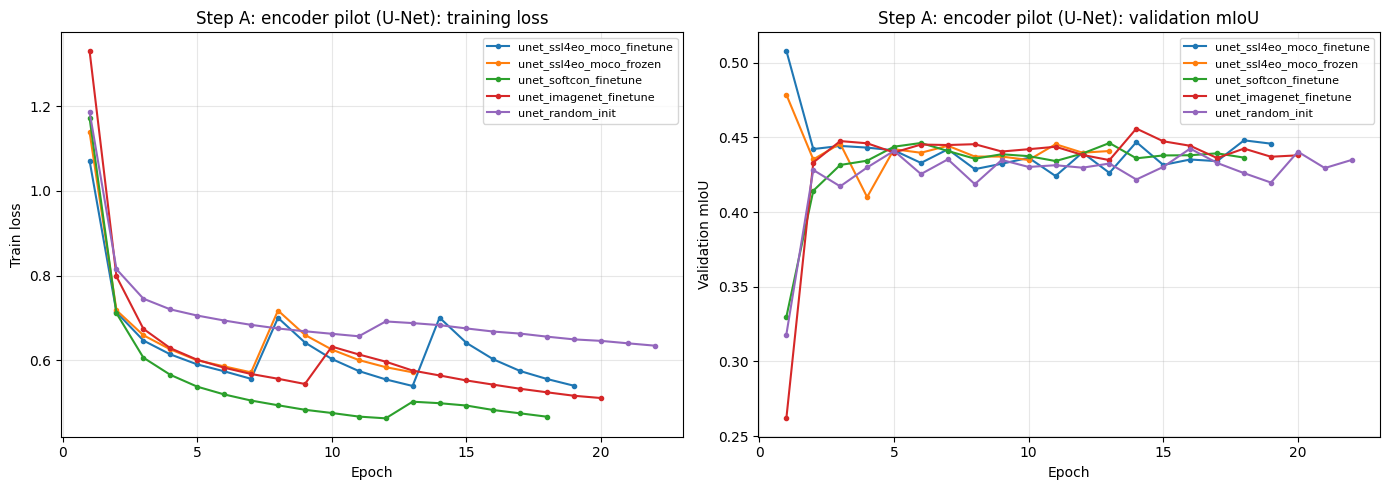

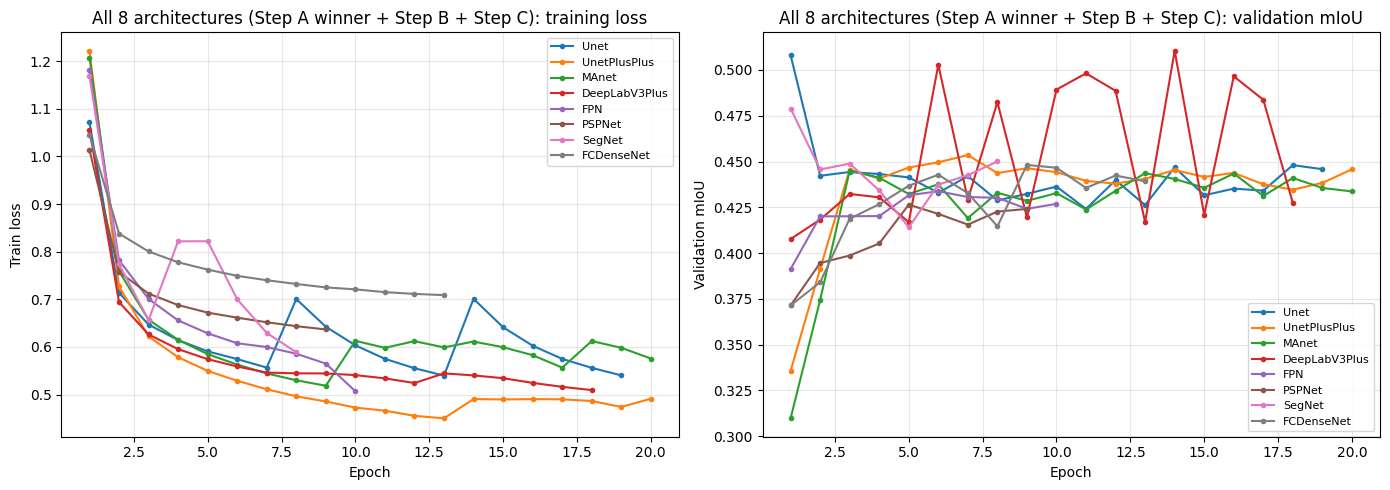

In [11]:
import matplotlib.pyplot as plt

def plot_training_curves(results_dict, title, keys=None):
    """results_dict maps a run name to {'history': [...], 'best_val_mIoU': float}.
    Each history entry is one epoch's logged metrics (see train_one_run's history.append call).
    Plots train loss and val mIoU side by side, one line per run, so model variants
    can be compared directly on the same two axes."""
    keys = keys or list(results_dict.keys())
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name in keys:
        history = results_dict[name]['history']
        if not history:
            continue
        epochs = [h['epoch'] for h in history]
        axes[0].plot(epochs, [h['train_loss'] for h in history], marker='o', markersize=3, label=name)
        axes[1].plot(epochs, [h['val_mIoU'] for h in history], marker='o', markersize=3, label=name)

    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Train loss')
    axes[0].set_title(f'{title}: training loss')
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Validation mIoU')
    axes[1].set_title(f'{title}: validation mIoU')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_training_curves(pilot_results, 'Step A: encoder pilot (U-Net)')
plot_training_curves(all_results, 'All 8 architectures (Step A winner + Step B + Step C)')


**Final evaluation:** all 8 models on the three test splits.

In [12]:
BEST_RUN_NAME = {
    'Unet': winner_name,
    'UnetPlusPlus': f'unetplusplus_{WINNER_ENCODER_SOURCE}',
    'MAnet': f'manet_{WINNER_ENCODER_SOURCE}',
    'DeepLabV3Plus': f'deeplabv3plus_{WINNER_ENCODER_SOURCE}',
    'FPN': f'fpn_{WINNER_ENCODER_SOURCE}',
    'PSPNet': f'pspnet_{WINNER_ENCODER_SOURCE}',
    'SegNet': 'segnet',
    'FCDenseNet': 'fcdensenet',
}

TEST_SPLITS = {
    'test_same_region': (test_same_region_df, False),
    'test_similar_unseen': (test_similar_unseen_df, False),
    'test_dissimilar': (test_dissimilar_df, False),
}
# (dataframe, add_vv_vh_diff) -- the diff channel is only added per-architecture below,
# since SegNet/FCDenseNet need 3 channels and the rest need 2.

from torch.utils.data import DataLoader

def rebuild_model_for_arch(arch):
    """Rebuilds the exact architecture/encoder combination used for that
    architecture's best run, so its saved checkpoint can be loaded into a
    freshly-constructed model with matching shapes. We don't retrain here."""
    if arch == 'SegNet':
        return build_model('SegNet', 'imagenet', num_classes=NUM_CLASSES)
    if arch == 'FCDenseNet':
        return build_model('FCDenseNet', 'random', num_classes=NUM_CLASSES)
    return build_model(arch, WINNER_ENCODER_SOURCE, num_classes=NUM_CLASSES,
                        in_channels=2, freeze_encoder=WINNER_FREEZE_ENCODER)


final_test_results = {}
for arch, run_name in BEST_RUN_NAME.items():
    needs_3ch = arch in ('SegNet', 'FCDenseNet')
    model = rebuild_model_for_arch(arch)

    ckpt_path = f'{CKPT_DIR}/{run_name}_best.pt'
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model = model.to(device)

    final_test_results[arch] = {}
    for split_name, (split_df, _) in TEST_SPLITS.items():
        ds = PatchDataset(split_df, PATCH_FOLDER, augment=False, add_vv_vh_diff=needs_3ch)
        loader = DataLoader(ds, batch_size=8, shuffle=False, drop_last=False, num_workers=0)
        metrics, cm = evaluate(model, loader, device, label=f'{arch}/{split_name}')
        final_test_results[arch][split_name] = {'metrics': metrics, 'confusion_matrix': cm.tolist()}
        print(f"{arch:15s} {split_name:22s} mIoU={metrics['mIoU']:.4f} OA={metrics['OA']:.4f} "
              f"macro_F1={metrics['macro_F1']:.4f} kappa={metrics['kappa']:.4f}")

    release_model(model)

print('\nAll 8 architectures evaluated on all 3 test splits.')


Downloading: "https://hf.co/torchgeo/resnet50_sentinel1_all_moco/resolve/e79862c667853c10a709bdd77ea8ffbad0e0f1cf/resnet50_sentinel1_all_moco-906e4356.pth" to /root/.cache/torch/hub/checkpoints/resnet50_sentinel1_all_moco-906e4356.pth


100%|██████████| 90.0M/90.0M [00:00<00:00, 99.2MB/s]


  [Unet/test_same_region] eval batch 20/96 (5s elapsed)
  [Unet/test_same_region] eval batch 40/96 (8s elapsed)
  [Unet/test_same_region] eval batch 60/96 (10s elapsed)
  [Unet/test_same_region] eval batch 80/96 (12s elapsed)
  [Unet/test_same_region] eval batch 96/96 (14s elapsed)
Unet            test_same_region       mIoU=0.3724 OA=0.7173 macro_F1=0.4645 kappa=0.6280
  [Unet/test_similar_unseen] eval batch 20/144 (2s elapsed)
  [Unet/test_similar_unseen] eval batch 40/144 (5s elapsed)
  [Unet/test_similar_unseen] eval batch 60/144 (7s elapsed)
  [Unet/test_similar_unseen] eval batch 80/144 (10s elapsed)
  [Unet/test_similar_unseen] eval batch 100/144 (12s elapsed)
  [Unet/test_similar_unseen] eval batch 120/144 (15s elapsed)
  [Unet/test_similar_unseen] eval batch 140/144 (17s elapsed)
  [Unet/test_similar_unseen] eval batch 144/144 (17s elapsed)
Unet            test_similar_unseen    mIoU=0.3326 OA=0.7222 macro_F1=0.4079 kappa=0.6059
  [Unet/test_dissimilar] eval batch 20/192 (2s e

100%|██████████| 528M/528M [00:05<00:00, 102MB/s] 


  [SegNet/test_same_region] eval batch 20/96 (4s elapsed)
  [SegNet/test_same_region] eval batch 40/96 (9s elapsed)
  [SegNet/test_same_region] eval batch 60/96 (13s elapsed)
  [SegNet/test_same_region] eval batch 80/96 (17s elapsed)
  [SegNet/test_same_region] eval batch 96/96 (21s elapsed)
SegNet          test_same_region       mIoU=0.4063 OA=0.6995 macro_F1=0.5145 kappa=0.6080
  [SegNet/test_similar_unseen] eval batch 20/144 (4s elapsed)
  [SegNet/test_similar_unseen] eval batch 40/144 (9s elapsed)
  [SegNet/test_similar_unseen] eval batch 60/144 (13s elapsed)
  [SegNet/test_similar_unseen] eval batch 80/144 (18s elapsed)
  [SegNet/test_similar_unseen] eval batch 100/144 (22s elapsed)
  [SegNet/test_similar_unseen] eval batch 120/144 (26s elapsed)
  [SegNet/test_similar_unseen] eval batch 140/144 (31s elapsed)
  [SegNet/test_similar_unseen] eval batch 144/144 (31s elapsed)
SegNet          test_similar_unseen    mIoU=0.3133 OA=0.6831 macro_F1=0.3932 kappa=0.5538
  [SegNet/test_dissim

**Comparison table:** all 8 architectures, sorted by same-region mIoU.

In [13]:
rows = []
for arch in BEST_RUN_NAME:
    row = {'architecture': arch, 'best_run': BEST_RUN_NAME[arch]}
    for split_name in TEST_SPLITS:
        m = final_test_results[arch][split_name]['metrics']
        row[f'{split_name}_mIoU'] = m['mIoU']
        row[f'{split_name}_OA'] = m['OA']
        row[f'{split_name}_macro_F1'] = m['macro_F1']
    rows.append(row)

comparison_df = pd.DataFrame(rows).sort_values('test_same_region_mIoU', ascending=False).reset_index(drop=True)
comparison_df.to_csv(f'{CKPT_DIR}/final_comparison_table.csv', index=False)
comparison_df


,architecture,best_run,test_same_region_mIoU,test_same_region_OA,test_same_region_macro_F1,test_similar_unseen_mIoU,test_similar_unseen_OA,test_similar_unseen_macro_F1,test_dissimilar_mIoU,test_dissimilar_OA,test_dissimilar_macro_F1
0,UnetPlusPlus,unetplusplus_ssl4eo_moco,0.453495,0.741890,0.557083,0.322619,0.697869,0.403956,0.226860,0.710436,0.280591
1,FPN,fpn_ssl4eo_moco,0.450487,0.732348,0.557661,0.330548,0.716871,0.409945,0.214168,0.683346,0.262751
2,PSPNet,pspnet_ssl4eo_moco,0.445427,0.713280,0.564771,0.330211,0.703453,0.417047,0.231672,0.688839,0.293806
3,FCDenseNet,fcdensenet,0.437414,0.716711,0.554487,0.327576,0.711394,0.414787,0.227832,0.711089,0.283452
4,DeepLabV3Plus,deeplabv3plus_ssl4eo_moco,0.430182,0.714616,0.539844,0.330276,0.713865,0.410202,0.214041,0.703784,0.258648
5,SegNet,segnet,0.406325,0.699451,0.514535,0.313290,0.683108,0.393239,0.222572,0.657252,0.279239
6,MAnet,manet_ssl4eo_moco,0.390268,0.706532,0.497279,0.346152,0.726589,0.431335,0.231068,0.720625,0.288929
7,Unet,unet_ssl4eo_moco_finetune,0.372363,0.717301,0.464484,0.332638,0.722152,0.407948,0.221680,0.729750,0.269220


**Per-class breakdown** for the winning architecture, same-region test.

In [14]:
best_arch = comparison_df.iloc[0]['architecture']
best_metrics = final_test_results[best_arch]['test_same_region']['metrics']

per_class_df = pd.DataFrame({
    'class': CLASS_NAMES,
    'IoU': best_metrics['per_class_IoU'],
    'F1': best_metrics['per_class_F1'],
}).sort_values('IoU', ascending=False).reset_index(drop=True)

print(f'Best architecture: {best_arch}')
per_class_df


Best architecture: UnetPlusPlus


,class,IoU,F1
0,Permanent water,0.838258,0.912013
1,Tree cover,0.623979,0.768457
2,Built-up,0.609219,0.757161
3,Cropland,0.584366,0.737665
4,Grassland,0.480171,0.648805
5,Herbaceous wetland,0.021178,0.041477
6,Bare/sparse vegetation,0.017296,0.034004
7,Shrubland,0.000000,0.000000
8,Mangroves,0.000000,0.000000


**Per-city breakdown** of the winning architecture, same-region test.

In [15]:
per_city_rows = []
for city in test_same_region_df['city'].unique():
    city_df = test_same_region_df[test_same_region_df['city'] == city].reset_index(drop=True)
    ds = PatchDataset(city_df, PATCH_FOLDER, augment=False,
                       add_vv_vh_diff=(best_arch in ('SegNet', 'FCDenseNet')))
    loader = DataLoader(ds, batch_size=8, shuffle=False, drop_last=False, num_workers=0)

    model = rebuild_model_for_arch(best_arch)
    model.load_state_dict(torch.load(f'{CKPT_DIR}/{BEST_RUN_NAME[best_arch]}_best.pt', map_location=device))
    model = model.to(device)

    metrics, _ = evaluate(model, loader, device, label=city)
    per_city_rows.append({'city': city, 'n_patches': len(city_df), 'mIoU': metrics['mIoU'],
                           'OA': metrics['OA'], 'macro_F1': metrics['macro_F1']})
    release_model(model)

per_city_df = pd.DataFrame(per_city_rows)
per_city_df


  [Bremen] eval batch 20/48 (5s elapsed)
  [Bremen] eval batch 40/48 (9s elapsed)
  [Bremen] eval batch 48/48 (11s elapsed)
  [Rostock] eval batch 20/48 (5s elapsed)
  [Rostock] eval batch 40/48 (9s elapsed)
  [Rostock] eval batch 48/48 (11s elapsed)


,city,n_patches,mIoU,OA,macro_F1
0,Bremen,384,0.404047,0.768259,0.498050
1,Rostock,384,0.444332,0.715520,0.545406
